In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import  files

In [2]:
os.makedirs('images', exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename(filename, dest)
  print(f'{filename} Is Successfully Uploaded To {dest}')

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Saving akhavan.jpg to akhavan.jpg
akhavan.jpg Is Successfully Uploaded To images/akhavan.jpg

Contents Of Images Folder:
['akhavan.jpg']


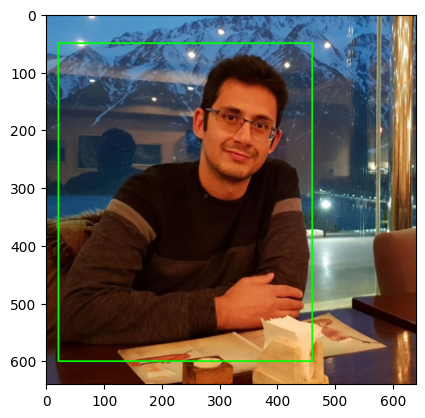

In [3]:
img = cv2.imread('images/akhavan.jpg')

rect = (21, 50, 460, 600)
cv2.rectangle(img, (rect[0], rect[1]), (rect[2], rect[3]), (0, 255, 0), 2)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

plt.show()

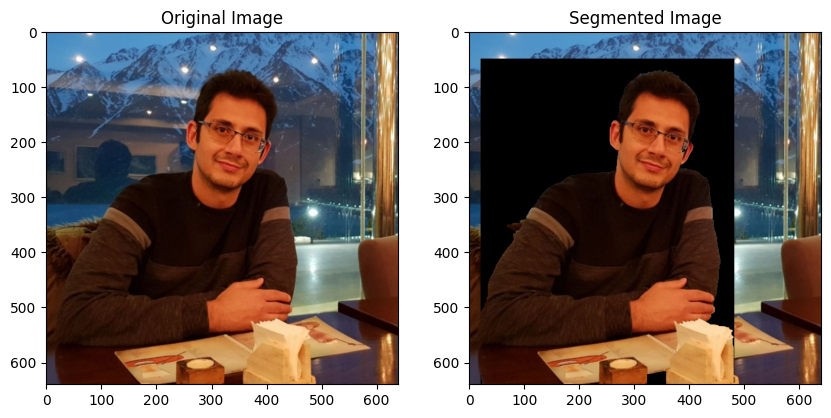

In [4]:
img = cv2.imread('images/akhavan.jpg')

mask = np.zeros(img.shape[:2], dtype=np.uint8)
bgdModel = np.zeros((1, 65), dtype=np.float64)
fgdModel = np.zeros((1, 65), dtype=np.float64)

rect = (21, 50, 460, 600)

cv2.grabCut(img, mask, rect, bgdModel, fgdModel, 5, cv2.GC_INIT_WITH_RECT)
mask = np.where(mask==2, 0, 1).astype('uint8')
result = img * mask[:, :, np.newaxis]

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img[..., ::-1])
plt.title('Original Image')

plt.subplot(1, 2, 2)
plt.imshow(result[..., ::-1])
plt.title('Segmented Image')

plt.show()

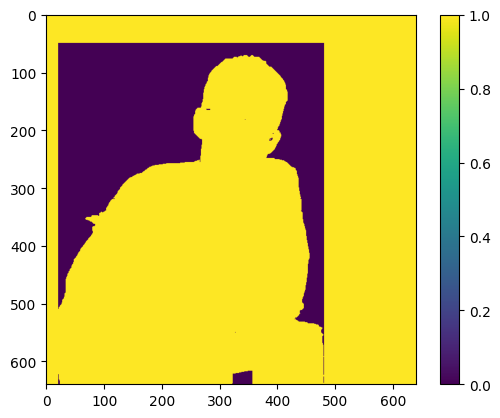

In [5]:
plt.imshow(mask)
plt.colorbar()

plt.show()

In [6]:
np.unique(mask)

array([0, 1], dtype=uint8)

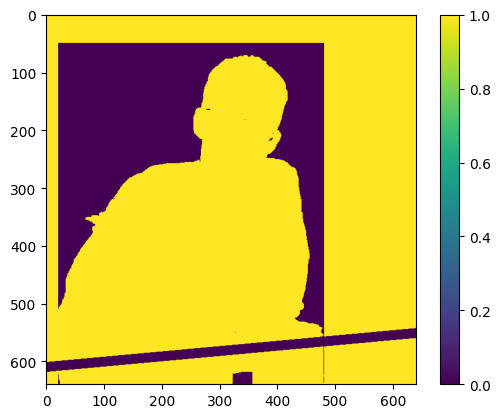

In [7]:
cv2.line(mask, (0, 610), (660, 550), cv2.GC_BGD, 15)
cv2.line(mask, (200, 610), (400, 610), cv2.GC_BGD, 15)
cv2.line(mask, (200, 610), (400, 610), cv2.GC_FGD, 15)

plt.imshow(mask)
plt.colorbar()

plt.show()

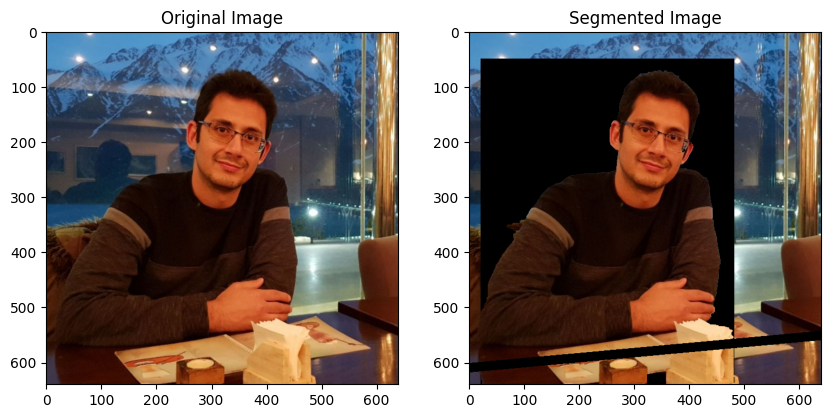

In [8]:
img = cv2.imread('images/akhavan.jpg')

bgdModel = np.zeros((1, 65), dtype=np.float64)
fgdModel = np.zeros((1, 65), dtype=np.float64)
cv2.grabCut(img, mask, rect, bgdModel, fgdModel, 5, cv2.GC_INIT_WITH_MASK)

mask2 = np.where((mask == cv2.GC_PR_BGD)|(mask == cv2.GC_BGD), 0, 1).astype('uint8')
result = img * mask[:, :, np.newaxis]

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img[..., ::-1])
plt.title('Original Image')

plt.subplot(1, 2, 2)
plt.imshow(result[..., ::-1])
plt.title('Segmented Image')

plt.show()